# Task 04 – Supervised Classification Modeling & Tuning
## Credit Default Risk Prediction

**Objective:** Train and compare four classification algorithms to predict loan default, tune their hyperparameters with `GridSearchCV` and stratified cross-validation, evaluate them using classification metrics, ROC-AUC and confusion matrices, and save the best validation model.

**Dataset:** `credit-default-risk.csv` (1,200 borrower records).  
**Target:** `loan_default` (0 = no default, 1 = default).

> This is an educational synthetic dataset. Model outputs must not be used to make real lending or credit decisions.

## 1. Import libraries

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
DATA_PATH = "credit-default-risk.csv"
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Load and inspect the dataset

In [2]:
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.info())
display(df["loan_default"].value_counts().rename("count").to_frame())
print("\\nMissing values:")
display(df.isnull().sum().to_frame("missing_count"))

Dataset shape: (1200, 12)


,age,annual_income,loan_amount,credit_score,employment_years,debt_to_income_ratio,loan_term_months,education,employment_type,home_ownership,loan_purpose,loan_default
0,25,93809.0,19896.0,672.0,7.8,0.254,36,High School,Self-employed,Mortgage,Home Improvement,0
1,59,45651.0,7907.0,640.0,3.4,0.474,48,Postgraduate,Contract,NaN,Education,1
2,53,61357.0,31161.0,829.0,6.5,0.496,48,High School,Salaried,Mortgage,Vehicle,0
3,42,18000.0,25283.0,674.0,22.9,0.043,60,Graduate,Self-employed,Mortgage,Education,1
4,42,29583.0,18859.0,780.0,8.0,0.170,60,Postgraduate,Salaried,Rent,Education,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1200 non-null   int64  
 1   annual_income         1157 non-null   float64
 2   loan_amount           1200 non-null   float64
 3   credit_score          1142 non-null   float64
 4   employment_years      1138 non-null   float64
 5   debt_to_income_ratio  1200 non-null   float64
 6   loan_term_months      1200 non-null   int64  
 7   education             1155 non-null   object 
 8   employment_type       1164 non-null   object 
 9   home_ownership        1170 non-null   object 
 10  loan_purpose          1200 non-null   object 
 11  loan_default          1200 non-null   int64  
dtypes: float64(5), int64(3), object(4)
memory usage: 112.6+ KB


None

,count
loan_default,
0,880
1,320


\nMissing values:


,missing_count
age,0
annual_income,43
loan_amount,0
credit_score,58
employment_years,62
debt_to_income_ratio,0
loan_term_months,0
education,45
employment_type,36
home_ownership,30


## 3. Separate features and target

In [3]:
X = df.drop(columns=["loan_default"])
y = df["loan_default"].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\\nTarget distribution:")
print(y.value_counts(normalize=True).round(3))

Numeric features: ['age', 'annual_income', 'loan_amount', 'credit_score', 'employment_years', 'debt_to_income_ratio', 'loan_term_months']
Categorical features: ['education', 'employment_type', 'home_ownership', 'loan_purpose']
\nTarget distribution:
loan_default
0    0.733
1    0.267
Name: proportion, dtype: float64


## 4. Train-test split and preprocessing

A stratified split keeps the class proportions similar in the training and test sets. Imputation, scaling, and one-hot encoding are placed inside a scikit-learn pipeline so preprocessing is fitted only on each training fold and does not leak test information.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training target proportions:")
print(y_train.value_counts(normalize=True).round(3))

Training rows: 960
Testing rows: 240
Training target proportions:
loan_default
0    0.733
1    0.267
Name: proportion, dtype: float64


## 5. Define four baseline model architectures

The four models are Logistic Regression, Random Forest, Extra Trees, and Gradient Boosting. All models use the same preprocessing pipeline for a fair comparison.

In [5]:
model_grids = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
        {"classifier__C": [0.1, 1.0, 10.0]}
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {"classifier__n_estimators": [150, 250],
         "classifier__max_depth": [None, 8],
         "classifier__min_samples_split": [2, 5]}
    ),
    "Extra Trees": (
        ExtraTreesClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {"classifier__n_estimators": [150, 250],
         "classifier__max_depth": [None, 8],
         "classifier__min_samples_split": [2, 5]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"classifier__n_estimators": [100, 150],
         "classifier__learning_rate": [0.05, 0.1],
         "classifier__max_depth": [2, 3]}
    )
}

## 6. Hyperparameter optimization with GridSearchCV

Each candidate is tuned using 3-fold `StratifiedKFold` cross-validation. ROC-AUC is used as the selection score because it evaluates how well a model separates the two classes across classification thresholds.

In [6]:
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
searches = {}
comparison_rows = []

for model_name, (estimator, param_grid) in model_grids.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", estimator)
    ])
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv_strategy,
        n_jobs=-1,
        refit=True,
        verbose=0
    )
    print(f"Training and tuning: {model_name}")
    search.fit(X_train, y_train)
    searches[model_name] = search
    comparison_rows.append({
        "Model": model_name,
        "Best CV ROC-AUC": search.best_score_,
        "Best Parameters": str(search.best_params_)
    })

cv_results = pd.DataFrame(comparison_rows).sort_values(
    "Best CV ROC-AUC", ascending=False
).reset_index(drop=True)
display(cv_results)
cv_results.to_csv(os.path.join(OUTPUT_DIR, "model_comparison_cv.csv"), index=False)

Training and tuning: Logistic Regression


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Training and tuning: Random Forest


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Training and tuning: Extra Trees


Training and tuning: Gradient Boosting


,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.666875,{'classifier__C': 0.1}
1,Random Forest,0.621058,"{'classifier__max_depth': 8, 'classifier__min_..."
2,Gradient Boosting,0.619462,"{'classifier__learning_rate': 0.05, 'classifie..."
3,Extra Trees,0.593843,"{'classifier__max_depth': 8, 'classifier__min_..."


## 7. Evaluate tuned models on the held-out test set

In [7]:
evaluation_rows = []
test_probabilities = {}
test_predictions = {}

for model_name, search in searches.items():
    model = search.best_estimator_
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    test_predictions[model_name] = predictions
    test_probabilities[model_name] = probabilities
    evaluation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

evaluation = pd.DataFrame(evaluation_rows).sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)
display(evaluation.round(4))
evaluation.to_csv(os.path.join(OUTPUT_DIR, "model_evaluation_test.csv"), index=False)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6042,0.3333,0.4844,0.3949,0.6318
1,Gradient Boosting,0.7583,0.8000,0.1250,0.2162,0.5960
2,Random Forest,0.7417,0.5333,0.2500,0.3404,0.5865
3,Extra Trees,0.6375,0.3231,0.3281,0.3256,0.5074


## 8. ROC-AUC curve comparison

The ROC curve shows the trade-off between the true-positive rate and false-positive rate at different thresholds. A larger AUC indicates stronger ranking/separation performance on this test set.

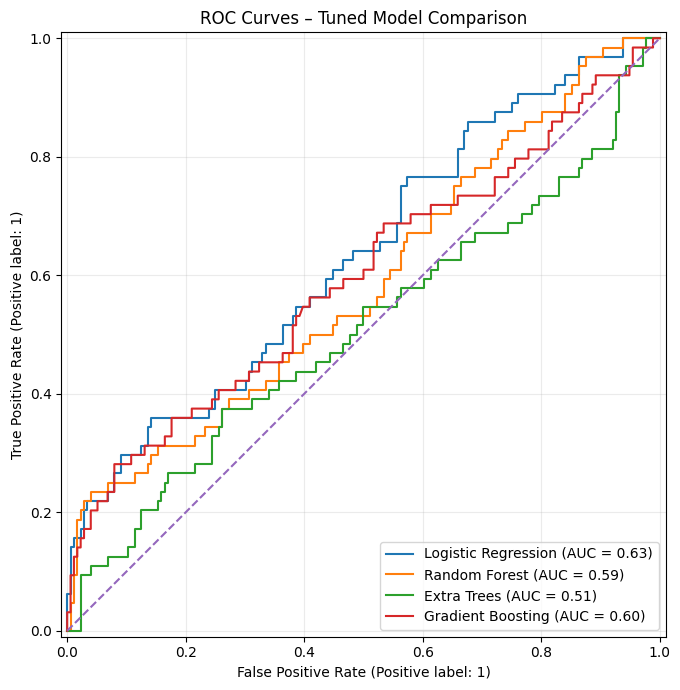

In [8]:
plt.figure(figsize=(9, 7))
ax = plt.gca()
for model_name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test, probabilities, name=model_name, ax=ax
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
ax.set_title("ROC Curves – Tuned Model Comparison")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_auc_curves.png"), dpi=160)
plt.show()

## 9. Confusion matrices

Confusion matrices summarize correct and incorrect predictions for each class. Class 1 represents a loan default and class 0 represents no default.

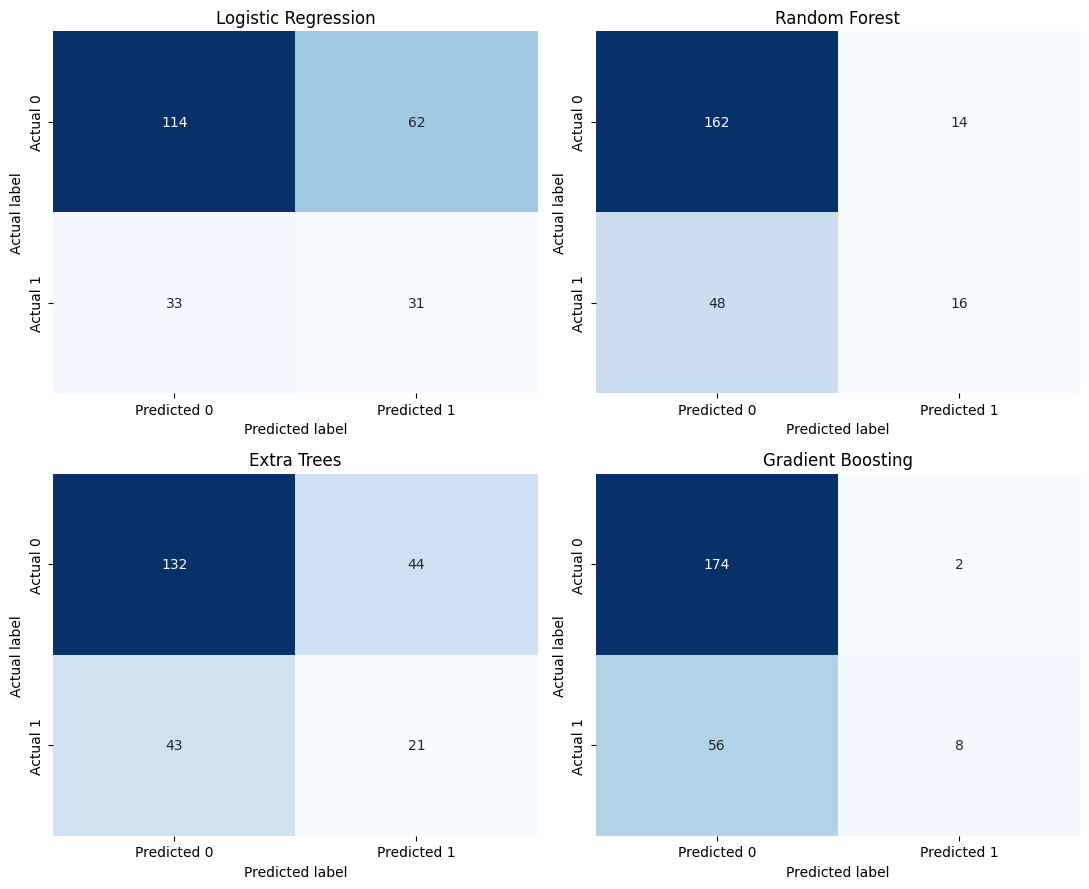

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (model_name, predictions) in zip(axes.ravel(), test_predictions.items()):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"]
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrices.png"), dpi=160)
plt.show()

## 10. Select the champion model and save it

The champion is selected using the highest **cross-validation ROC-AUC** from the training data, not the held-out test score. This keeps the test set reserved for final evaluation.

In [10]:
champion_name = cv_results.loc[0, "Model"]
champion_search = searches[champion_name]
champion_model = champion_search.best_estimator_

print("Champion model:", champion_name)
print("Best CV ROC-AUC:", round(champion_search.best_score_, 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, champion_model.predict_proba(X_test)[:, 1]), 4))
print("\\nClassification report:")
print(classification_report(y_test, champion_model.predict(X_test), zero_division=0))

joblib.dump(champion_model, os.path.join(OUTPUT_DIR, "champion_model.joblib"))
with open(os.path.join(OUTPUT_DIR, "champion_model_info.txt"), "w") as file:
    file.write(f"Champion model: {champion_name}\\n")
    file.write(f"Best CV ROC-AUC: {champion_search.best_score_:.6f}\\n")
    file.write(f"Best parameters: {champion_search.best_params_}\\n")
print("Saved champion model and model information in outputs/")

Champion model: Logistic Regression
Best CV ROC-AUC: 0.6669
Test ROC-AUC: 0.6318
\nClassification report:
              precision    recall  f1-score   support

           0       0.78      0.65      0.71       176
           1       0.33      0.48      0.39        64

    accuracy                           0.60       240
   macro avg       0.55      0.57      0.55       240
weighted avg       0.66      0.60      0.62       240

Saved champion model and model information in outputs/


## 11. Final conclusion

This notebook trained and tuned four classification models for the `loan_default` target. The comparison table reports stratified cross-validation ROC-AUC and held-out test metrics. The selected champion model is saved as `outputs/champion_model.joblib`.

**Responsible-use note:** The dataset is synthetic and may contain artificial patterns or imbalance. This experiment is for learning only; it is not a validated credit-scoring system and should not be used to approve or reject real applicants.

In [11]:
print("Generated output files:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

Generated output files:
- champion_model.joblib
- champion_model_info.txt
- confusion_matrices.png
- model_comparison_cv.csv
- model_evaluation_test.csv
- roc_auc_curves.png
